In [1]:
from pathlib import Path
from math import gcd, ceil, log2
from time import perf_counter
from hashlib import sha256
import json

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Same window selection and train/val/test manifest as PANNs.
CONTEXT_SECONDS = 2.0
FEATURE_SR = 16_000  # cheap MFCC frontend; PANNs used 32 kHz
N_FFT = 512
HOP_LENGTH = 160
N_MELS = 40
N_MFCC = 20
TARGET_ANIMAL_RECALL = 0.95
SEED = 42

# Speed controls: 24 test windows, two repeats for CPU timing.
BENCHMARK_PER_CLASS = 12
BENCHMARK_REPEATS = 2


def find_project_root():
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / "data" / "metadata" / "benchmark_2_audio_model_manifest.csv").is_file():
            return folder.resolve()
    raise FileNotFoundError(
        "Run Jupyter from your project root or Audio/; cannot locate "
        "data/metadata/benchmark_2_audio_model_manifest.csv"
    )

ROOT = find_project_root()
AUDIO_DIR = ROOT / "Audio"
if not AUDIO_DIR.is_dir():
    AUDIO_DIR = ROOT / "audio"
DATA_DIR = ROOT / "data"
MANIFEST_PATH = DATA_DIR / "metadata" / "benchmark_2_audio_model_manifest.csv"
CACHE_DIR = DATA_DIR / "audio_cache" / "full"
RESULTS_DIR = AUDIO_DIR / "results" / "mfcc_gate"
MODELS_DIR = AUDIO_DIR / "models" / "mfcc_gate"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE = RESULTS_DIR / "mfcc_features_2p0s_16k.npz"

print("Root:", ROOT)
print("Manifest:", MANIFEST_PATH)
print("Audio cache:", CACHE_DIR)
print("Output:", RESULTS_DIR)

Root: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project
Manifest: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\data\metadata\benchmark_2_audio_model_manifest.csv
Audio cache: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\data\audio_cache\full
Output: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\mfcc_gate


In [2]:
data = pd.read_csv(MANIFEST_PATH)
required = {"sample_id", "event_id", "file_id", "binary_label", "dataset_split",
            "start_2s", "end_2s"}
missing = required - set(data.columns)
assert not missing, f"Missing manifest fields: {sorted(missing)}"
assert data.sample_id.is_unique, "Duplicate sample_id would invalidate feature alignment"
assert set(data.dataset_split.unique()) == {"train", "val", "test"}
assert set(data.binary_label.unique()) == {0, 1}
assert data.groupby("event_id").dataset_split.nunique().max() == 1, "Event leakage across splits"
assert np.allclose(data.end_2s - data.start_2s, CONTEXT_SECONDS, atol=0.002)

# Preserve manifest row order; feature arrays and labels always use this order.
data = data.reset_index(drop=True)
for split in ("train", "val", "test"):
    subset = data[data.dataset_split.eq(split)]
    print(f"{split:5}: {len(subset):4} windows | "
          f"{int((subset.binary_label == 1).sum()):3} animal | "
          f"{int((subset.binary_label == 0).sum()):3} background")

paths = [CACHE_DIR / (str(file_id) + ".flac") for file_id in data.file_id]
missing_files = [path for path in set(paths) if not path.is_file()]
if missing_files:
    print("Example missing FLAC files:", *missing_files[:5], sep="\n - ")
    raise FileNotFoundError(f"Missing {len(missing_files)} cached soundtrack(s). "
                            "Create the complete cache with Prepare_Audio_Data.ipynb first.")
print(f"Audio cached: {len(set(paths))} / {len(set(paths))} original soundtrack files")

train:  556 windows | 436 animal | 120 background
val  :  145 windows | 115 animal |  30 background
test :  207 windows | 123 animal |  84 background
Audio cached: 779 / 779 original soundtrack files


In [3]:
FEATURE_CONFIG = dict(sample_rate=FEATURE_SR, seconds=CONTEXT_SECONDS, n_fft=N_FFT,
                      hop_length=HOP_LENGTH, n_mels=N_MELS, n_mfcc=N_MFCC,
                      center=False, features="mfcc_mean_std")


def read_window(row, return_source_sr=False):
    path = CACHE_DIR / (str(row["file_id"]) + ".flac")
    with sf.SoundFile(str(path)) as audio:
        sr = int(audio.samplerate)
        audio.seek(round(float(row["start_2s"]) * sr))
        waveform = audio.read(frames=round(CONTEXT_SECONDS * sr),
                              dtype="float32", always_2d=False)
    if waveform.ndim == 2:
        waveform = waveform.mean(axis=1)
    if sr != FEATURE_SR:
        common = gcd(sr, FEATURE_SR)
        waveform = resample_poly(waveform, up=FEATURE_SR // common,
                                 down=sr // common).astype(np.float32)
    wanted = round(FEATURE_SR * CONTEXT_SECONDS)
    if len(waveform) < wanted:
        # Match the PANNs approach: only pad a slightly short file tail.
        if len(waveform) < wanted - round(0.05 * FEATURE_SR):
            raise ValueError(f"Window too short: {row['sample_id']}, {len(waveform)} samples")
        waveform = np.pad(waveform, (0, wanted-len(waveform)))
    waveform = np.clip(waveform[:wanted], -1, 1).astype(np.float32, copy=False)
    return (waveform, sr) if return_source_sr else waveform


def mfcc_features(waveform):
    mfcc = librosa.feature.mfcc(
        y=waveform, sr=FEATURE_SR, n_mfcc=N_MFCC, n_mels=N_MELS,
        n_fft=N_FFT, hop_length=HOP_LENGTH, center=False,
    )
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)]).astype(np.float32)


def extract_one(row):
    return mfcc_features(read_window(row))

# Cache features so rerunning LR/RF training is instantaneous.
manifest_key_columns = ["sample_id", "file_id", "dataset_split", "binary_label", "start_2s", "end_2s"]
cache_key = sha256((data[manifest_key_columns].to_csv(index=False) +
                   json.dumps(FEATURE_CONFIG, sort_keys=True)).encode()).hexdigest()

if FEATURE_CACHE.exists():
    with np.load(FEATURE_CACHE) as old:
        valid = (str(old["cache_key"].item()) == cache_key and
                 np.array_equal(old["sample_id"], data.sample_id.astype(str).to_numpy()))
        X = old["X"].copy() if valid else None
else:
    X = None

if X is None:
    print(f"Extracting MFCC features for {len(data)} two-second windows...")
    t_start = perf_counter()
    X = np.vstack([extract_one(row) for _, row in data.iterrows()])
    np.savez_compressed(FEATURE_CACHE, X=X,
                        sample_id=data.sample_id.astype(str).to_numpy(), cache_key=cache_key)
    print(f"Feature extraction completed in {perf_counter() - t_start:.1f} s")
else:
    print("Loaded existing cached features:", FEATURE_CACHE)

assert X.shape == (len(data), 2 * N_MFCC)
assert np.isfinite(X).all(), "MFCCs contain non-finite values"
y = data.binary_label.to_numpy(dtype=int)
masks = {split: data.dataset_split.eq(split).to_numpy() for split in ("train", "val", "test")}
print("Feature matrix:", X.shape, "| 20 MFCC means + 20 standard deviations")

Extracting MFCC features for 908 two-second windows...


C:\Users\benja\anaconda3\envs\BDE\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Feature extraction completed in 6.8 s
Feature matrix: (908, 40) | 20 MFCC means + 20 standard deviations


In [4]:
models = {
    "MFCC + LR": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    ),
    "MFCC + RF": RandomForestClassifier(
        n_estimators=120, min_samples_leaf=2, max_depth=12,
        class_weight="balanced", random_state=SEED, n_jobs=1,
    ),
}

for name, model in models.items():
    begin = perf_counter()
    model.fit(X[masks["train"]], y[masks["train"]])
    print(f"{name}: trained in {perf_counter()-begin:.2f} s")

MFCC + LR: trained in 0.03 s
MFCC + RF: trained in 0.21 s


In [5]:
def choose_threshold(y_true, animal_proba, target_recall=TARGET_ANIMAL_RECALL):
    positive = (np.asarray(y_true) == 1)
    assert positive.any() and (~positive).any(), "Validation must have both labels"
    candidate_thresholds = np.unique(np.r_[0.0, animal_proba, 1.0])
    feasible = [float(t) for t in candidate_thresholds
                if np.mean(np.asarray(animal_proba)[positive] >= t) >= target_recall]
    if not feasible:
        raise ValueError("No feasible validation threshold")
    return max(feasible)

thresholds = {}
for name, model in models.items():
    p_val = model.predict_proba(X[masks["val"]])[:, 1]
    thresholds[name] = choose_threshold(y[masks["val"]], p_val)
    print(f"{name}: validation threshold = {thresholds[name]:.6f}")

MFCC + LR: validation threshold = 0.159498
MFCC + RF: validation threshold = 0.373453


In [6]:
def quality_metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, pred),
        "animal_recall": recall_score(y_true, pred, zero_division=0),
        "background_rejection": tn/(tn+fp) if tn+fp else np.nan,
        "animal_precision": precision_score(y_true, pred, zero_division=0),
        "animal_f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
        "video_activation_rate": float(pred.mean()),
        "vision_skip_rate": float(1-pred.mean()),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

metrics_rows = []
predictions_rows = []
for name, model in models.items():
    for split in ("val", "test"):
        mask = masks[split]
        prob = model.predict_proba(X[mask])[:, 1]
        metrics_rows.append({"model": name, "split": split,
                             "threshold": thresholds[name], "samples": int(mask.sum()),
                             **quality_metrics(y[mask], prob, thresholds[name])})
        selected = data.loc[mask, ["sample_id", "event_id", "site_id", "binary_label"]].copy()
        selected["model"] = name
        selected["split"] = split
        selected["animal_probability"] = prob
        selected["threshold"] = thresholds[name]
        selected["audio_prediction"] = (prob >= thresholds[name]).astype(int)
        predictions_rows.append(selected)

metrics = pd.DataFrame(metrics_rows)
predictions = pd.concat(predictions_rows, ignore_index=True)
display(metrics[["model", "split", "samples", "threshold", "accuracy", "animal_recall",
                 "background_rejection", "animal_f1", "roc_auc", "pr_auc",
                 "vision_skip_rate", "fn", "fp"]].round(4))

,model,split,samples,threshold,accuracy,animal_recall,background_rejection,animal_f1,roc_auc,pr_auc,vision_skip_rate,fn,fp
0,MFCC + LR,val,145,0.1595,0.9034,0.9565,0.7000,0.9402,0.9206,0.9503,0.1793,5,9
1,MFCC + LR,test,207,0.1595,0.9179,0.9837,0.8214,0.9344,0.9505,0.9546,0.3430,2,15
2,MFCC + RF,val,145,0.3735,0.8966,0.9565,0.6667,0.9362,0.9438,0.9853,0.1724,5,10
3,MFCC + RF,test,207,0.3735,0.8792,0.9675,0.7500,0.9049,0.9489,0.9548,0.3237,4,21


In [7]:
# Balanced benchmark subset, identical for both classifiers.
rng = np.random.default_rng(SEED)
benchmark_indices = []
for label in (0, 1):
    indices = np.flatnonzero(masks["test"] & (y == label))
    benchmark_indices.extend(rng.choice(indices, size=min(BENCHMARK_PER_CLASS, len(indices)), replace=False))
benchmark_indices = sorted(benchmark_indices)
print("CPU benchmark windows:", len(benchmark_indices), "| repeats:", BENCHMARK_REPEATS)

# Warm up librosa/scipy (avoid charging first-call imports/JIT to a sample).
_warm_wave, _warm_sr = read_window(data.iloc[benchmark_indices[0]], return_source_sr=True)
_ = mfcc_features(_warm_wave)
for model in models.values():
    _ = model.predict_proba(mfcc_features(_warm_wave)[None, :])

latency_rows = []
source_sample_rates = []
for idx in benchmark_indices:
    row = data.iloc[idx]
    _, source_sr = read_window(row, return_source_sr=True)
    source_sample_rates.append(source_sr)
    for repeat in range(BENCHMARK_REPEATS):
        t0 = perf_counter()
        wav = read_window(row)
        t1 = perf_counter()
        features = mfcc_features(wav)[None, :]
        t2 = perf_counter()
        for name, model in models.items():
            m0 = perf_counter()
            _ = model.predict_proba(features)[0, 1]
            m1 = perf_counter()
            latency_rows.append({
                "model": name, "sample_id": row.sample_id, "repeat": repeat,
                "read_resample_ms": (t1-t0)*1e3,
                "mfcc_ms": (t2-t1)*1e3,
                "model_ms": (m1-m0)*1e3,
                "total_ms": (t2-t0+m1-m0)*1e3,
            })

latencies = pd.DataFrame(latency_rows)
cost = (latencies.groupby("model")
        .agg(median_read_resample_ms=("read_resample_ms", "median"),
             median_mfcc_ms=("mfcc_ms", "median"),
             median_model_ms=("model_ms", "median"),
             median_total_ms=("total_ms", "median"),
             p90_total_ms=("total_ms", lambda a: np.percentile(a,90)))
        .reset_index())
cost["estimated_CPU_seconds_per_hour"] = cost.median_total_ms * (3600/CONTEXT_SECONDS) / 1000
print("The per-hour estimate assumes non-overlapping windows and includes cached-FLAC read time.")
display(cost.round(3))

CPU benchmark windows: 24 | repeats: 2
The per-hour estimate assumes non-overlapping windows and includes cached-FLAC read time.


,model,median_read_resample_ms,median_mfcc_ms,median_model_ms,median_total_ms,p90_total_ms,estimated_CPU_seconds_per_hour
0,MFCC + LR,3.32,1.785,0.563,5.716,6.259,10.289
1,MFCC + RF,3.32,1.785,5.304,10.370,11.542,18.666


In [8]:
def approx_frontend_ops(source_sr):
    num_out = round(FEATURE_SR * CONTEXT_SECONDS)
    n_frames = 1 + (num_out - N_FFT) // HOP_LENGTH
    n_freq = N_FFT // 2 + 1
    # Widely used coarse FFT complexity proxy (not hardware profiling).
    fft_ops = n_frames * 5 * N_FFT * log2(N_FFT)
    power_ops = n_frames * n_freq * 3
    mel_ops = n_frames * 2 * N_MELS * n_freq  # dense mel multiplication approximation
    log_ops = n_frames * N_MELS * 10  # rough nonlinear-op equivalent
    dct_ops = n_frames * 2 * N_MFCC * N_MELS
    pooling_ops = n_frames * N_MFCC * 4
    if source_sr == FEATURE_SR:
        resample_ops = 0
    else:
        div = gcd(source_sr, FEATURE_SR)
        up, down = FEATURE_SR // div, source_sr // div
        # scipy.signal.resample_poly default FIR prototype is ~20*max(up,down)+1 taps.
        filter_taps = 20 * max(up, down) + 1
        resample_ops = num_out * 2 * ceil(filter_taps / up)
    return fft_ops + power_ops + mel_ops + log_ops + dct_ops + pooling_ops + resample_ops

approx_mops = np.mean([approx_frontend_ops(sr) for sr in source_sample_rates]) / 1e6
print(f"Rough MFCC + resampling budget: {approx_mops:.3f} million operations "
      f"({approx_mops/1000:.5f} GOPs) per 2-second window")

head_cost = []
for name, model in models.items():
    if name.endswith("LR"):
        # Includes a rough 2 operations per feature for standardization and LR dot product.
        head_cost.append({"model": name, "head_cost_kind": "linear floating-point ops (approx)",
                          "head_operations_or_comparisons": 4 * X.shape[1] + 2})
    else:
        # Number of tree nodes visited is the natural cost proxy for RF (comparisons).
        path, _ = model.decision_path(X[masks["test"]])
        avg_nodes = float(np.asarray(path.getnnz(axis=1)).mean())
        head_cost.append({"model": name, "head_cost_kind": "tree node visits (comparisons)",
                          "head_operations_or_comparisons": avg_nodes})
head_cost = pd.DataFrame(head_cost)
cost = cost.merge(head_cost, on="model")
cost["approx_frontend_mops"] = approx_mops
cost["approx_frontend_gops"] = approx_mops / 1000

display(cost[["model", "approx_frontend_mops", "head_cost_kind", "head_operations_or_comparisons",
              "median_mfcc_ms", "median_model_ms", "median_total_ms", "p90_total_ms"]].round(3))

Rough MFCC + resampling budget: 12.735 million operations (0.01273 GOPs) per 2-second window


,model,approx_frontend_mops,head_cost_kind,head_operations_or_comparisons,median_mfcc_ms,median_model_ms,median_total_ms,p90_total_ms
0,MFCC + LR,12.735,linear floating-point ops (approx),162.000,1.785,0.563,5.716,6.259
1,MFCC + RF,12.735,tree node visits (comparisons),850.024,1.785,5.304,10.370,11.542


FINAL TEST COMPARISON (95% recall was a VALIDATION target, not a test guarantee)


,model,samples,threshold,accuracy,animal_recall,background_rejection,animal_precision,animal_f1,roc_auc,pr_auc,...,fn,fp,median_total_ms,p90_total_ms,median_mfcc_ms,median_model_ms,estimated_CPU_seconds_per_hour,approx_frontend_gops,head_cost_kind,head_operations_or_comparisons
0,MFCC + LR,207,0.1595,0.9179,0.9837,0.8214,0.8897,0.9344,0.9505,0.9546,...,2,15,5.7159,6.2586,1.7849,0.5635,10.2887,0.0127,linear floating-point ops (approx),162.0000
1,MFCC + RF,207,0.3735,0.8792,0.9675,0.7500,0.8500,0.9049,0.9489,0.9548,...,4,21,10.3702,11.5418,1.7849,5.3037,18.6663,0.0127,tree node visits (comparisons),850.0242


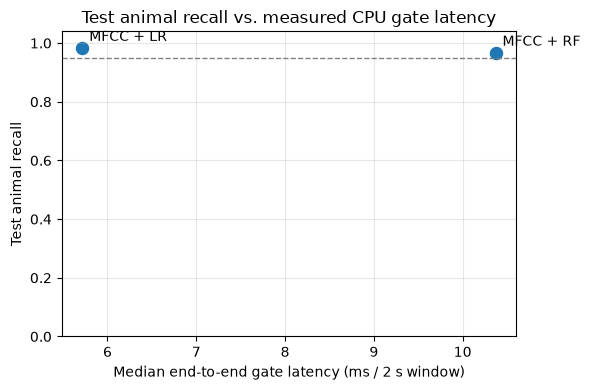

Saved results to C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\mfcc_gate
Saved deployable models to C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\models\mfcc_gate


In [9]:
test_metrics = metrics[metrics.split.eq("test")].copy()
comparison = test_metrics.merge(cost, on="model")
comparison = comparison[[
    "model", "samples", "threshold", "accuracy", "animal_recall", "background_rejection",
    "animal_precision", "animal_f1", "roc_auc", "pr_auc", "vision_skip_rate",
    "fn", "fp", "median_total_ms", "p90_total_ms", "median_mfcc_ms", "median_model_ms",
    "estimated_CPU_seconds_per_hour", "approx_frontend_gops", "head_cost_kind",
    "head_operations_or_comparisons",
]]

print("FINAL TEST COMPARISON (95% recall was a VALIDATION target, not a test guarantee)")
display(comparison.round(4))

metrics.to_csv(RESULTS_DIR / "mfcc_lr_rf_metrics_val_test.csv", index=False)
predictions.to_csv(RESULTS_DIR / "mfcc_lr_rf_predictions_val_test.csv", index=False)
latencies.to_csv(RESULTS_DIR / "mfcc_lr_rf_cpu_latency_samples.csv", index=False)
comparison.to_csv(RESULTS_DIR / "mfcc_lr_rf_test_comparison.csv", index=False)

for name, model in models.items():
    slug = "lr" if name.endswith("LR") else "rf"
    joblib.dump({"model": model, "animal_threshold": thresholds[name],
                 "feature_config": FEATURE_CONFIG, "target_animal_recall": TARGET_ANIMAL_RECALL},
                MODELS_DIR / f"mfcc_{slug}_2p0s.joblib")

config = {"feature_config": FEATURE_CONFIG, "validation_recall_target": TARGET_ANIMAL_RECALL,
          "manifest": str(MANIFEST_PATH), "splits": data.dataset_split.value_counts().to_dict(),
          "thresholds": thresholds, "seed": SEED,
          "benchmark_samples": len(benchmark_indices),
          "benchmark_repeats": BENCHMARK_REPEATS,
          "cost_caveat": "approx_frontend_gops is an analytical heuristic, NOT profiled FLOPs or energy"}
(RESULTS_DIR / "mfcc_lr_rf_config.json").write_text(json.dumps(config, indent=2))

ax = comparison.plot.scatter(x="median_total_ms", y="animal_recall", figsize=(6, 4), s=75)
for _, r in comparison.iterrows():
    ax.annotate(r.model, (r.median_total_ms, r.animal_recall), xytext=(5, 5), textcoords="offset points")
ax.axhline(TARGET_ANIMAL_RECALL, color="gray", linestyle="--", linewidth=1, label="Validation target (95%)")
ax.set(title="Test animal recall vs. measured CPU gate latency",
       xlabel="Median end-to-end gate latency (ms / 2 s window)", ylabel="Test animal recall", ylim=(0, 1.04))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mfcc_lr_rf_test_recall_vs_latency.png", dpi=180)
plt.show()

print("Saved results to", RESULTS_DIR)
print("Saved deployable models to", MODELS_DIR)